## Experiment 6: Data Aggregation

**Aim:** To analyze and visualize retail sales data by aggregating and comparing sales across regions and product categories.

In [1]:
# A52 Dipanshu Ambilkar
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
np.random.seed(5)
n = 400
df = pd.DataFrame({
    "date": pd.to_datetime(np.random.choice(pd.date_range("2026-01-01", periods=180), n)),
    "region": np.random.choice(["North", "South", "East", "West"], n),
    "category": np.random.choice(["Electronics", "Clothing", "Grocery", "Furniture"], n),
    "quantity": np.random.randint(1, 10, n),
    "amount": np.round(np.random.uniform(100, 5000, n), 2),
})
df.head()

,date,region,category,quantity,amount
0,2026-04-10,South,Grocery,6,597.37
1,2026-04-29,West,Electronics,5,2115.81
2,2026-05-25,South,Grocery,3,4366.17
3,2026-03-15,East,Grocery,1,1099.17
4,2026-01-09,South,Electronics,7,1825.91


In [3]:
print("total rows:", df.shape)

total rows: (400, 5)


In [4]:
by_region = df.groupby("region")["amount"].sum().sort_values(ascending=False)
by_region

region
East     302415.93
South    277106.73
North    238128.91
West     214866.47
Name: amount, dtype: float64

In [5]:
print("Top region:", by_region.index[0])

Top region: East


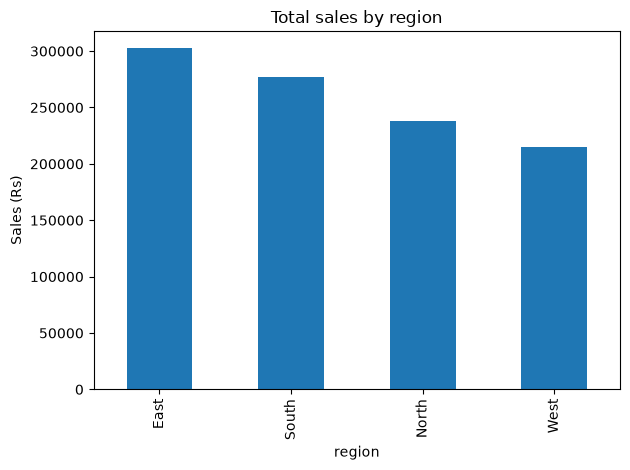

In [6]:
by_region.plot(kind="bar")
plt.title("Total sales by region")
plt.ylabel("Sales (Rs)")
plt.tight_layout()
plt.show()

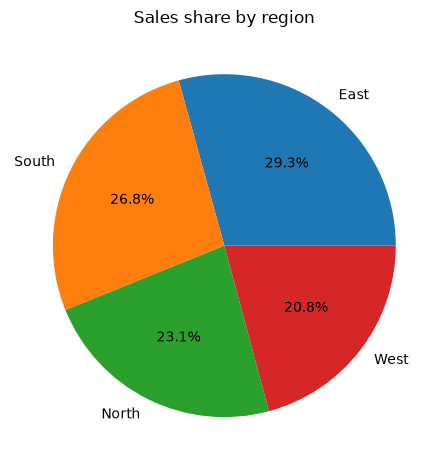

In [7]:
by_region.plot(kind="pie", autopct="%1.1f%%")
plt.title("Sales share by region")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [8]:
by_both = df.groupby(["region", "category"])["amount"].sum().unstack()
print(by_both)

category  Clothing  Electronics  Furniture   Grocery
region                                              
East      69210.35     92355.88   64309.44  76540.26
North     70766.43     68569.85   42383.33  56409.30
South     56336.63     71520.16   70409.72  78840.22
West      42871.62     62501.51   75803.58  33689.76


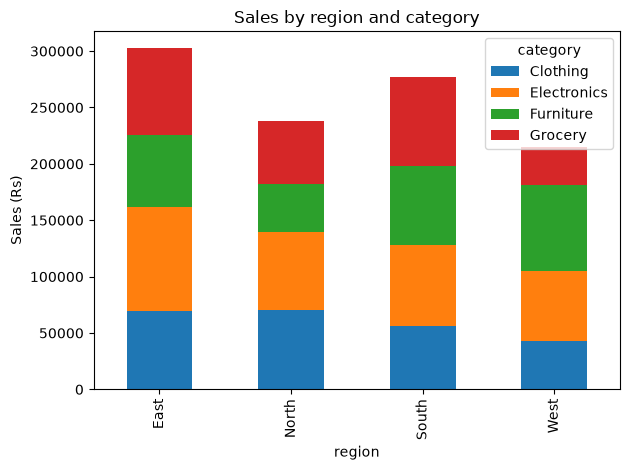

In [9]:
by_both.plot(kind="bar", stacked=True)
plt.title("Sales by region and category")
plt.ylabel("Sales (Rs)")
plt.tight_layout()
plt.show()

In [10]:
df["month"] = df["date"].dt.to_period("M").astype(str)
df.head()

,date,region,category,quantity,amount,month
0,2026-04-10,South,Grocery,6,597.37,2026-04
1,2026-04-29,West,Electronics,5,2115.81,2026-04
2,2026-05-25,South,Grocery,3,4366.17,2026-05
3,2026-03-15,East,Grocery,1,1099.17,2026-03
4,2026-01-09,South,Electronics,7,1825.91,2026-01


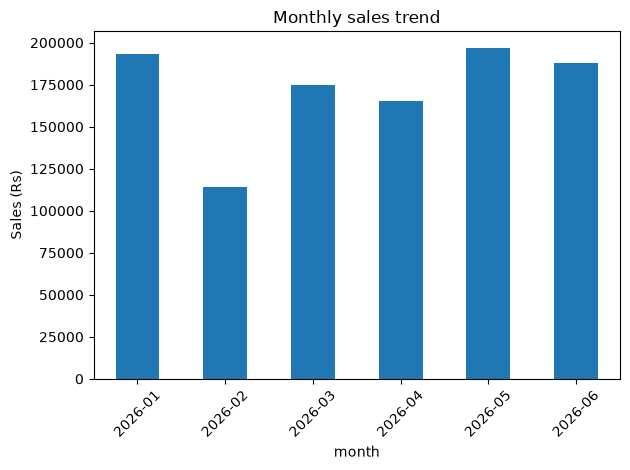

In [11]:
df.groupby("month")["amount"].sum().plot(kind="bar")
plt.title("Monthly sales trend")
plt.ylabel("Sales (Rs)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
print("done")

done
